# The Quadrupole Wavefunction as a Surface

**l = 2 hydrogen states and the multipole expansion** — companion to
[`dgs/quadrupole_wavefunction.py`](../dgs/quadrupole_wavefunction.py).

An electron in a *d* state ($l=2$) has the angular wavefunction
$Y_2^m(\theta,\phi)$. Two courses meet in that one function:

| Course | Where $l=2$ appears | Reading |
|---|---|---|
| Quantum mechanics | angular part of the hydrogen wavefunction $\psi_{nlm}=R_{nl}\,Y_l^m$ | Griffiths & Schroeter [1], Sec. 4.1.2 and 4.2 |
| Electrodynamics | the **quadrupole** term of the multipole expansion, $\propto P_2(\cos\theta)/r^3$ | Griffiths [2], Sec. 3.4 |

The claim this notebook checks numerically: the probability cloud of a
$d$ electron is not spherical, so far away it produces a point-charge
potential **plus a quadrupole term** with exactly the angular shape of
$Y_2^0$.

**Units.** Lengths in Bohr radii $a$, charge in units of the particle's
charge, potential in units of charge$/(4\pi\varepsilon_0a)$.

**What the pictures are not.** The surface $r=|Y(\theta,\phi)|$ is a plot of
an angular function. It is not the shape of the electron and not a surface
the electron moves on.

In [1]:
import sys, pathlib, math
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm

from dgs.quadrupole_wavefunction import (
    D_ORBITALS, spherical_harmonic, real_d_orbital, orbital_surface,
    radial_wavefunction, hydrogen_psi, mean_r2, mean_cos2,
    quadrupole_moment_zz, quadrupole_tensor, orbital_potential, far_field_potential,
)
from dgs import electrostatics_multipoles as em
print("using dgs.quadrupole_wavefunction and dgs.electrostatics_multipoles directly")

using dgs.quadrupole_wavefunction and dgs.electrostatics_multipoles directly


# Part 1 — The five $l=2$ functions

$$Y_2^0=\sqrt{\tfrac{5}{16\pi}}\,(3\cos^2\theta-1),\qquad
Y_2^{\pm1}=\mp\sqrt{\tfrac{15}{8\pi}}\,\sin\theta\cos\theta\,e^{\pm i\phi},\qquad
Y_2^{\pm2}=\sqrt{\tfrac{15}{32\pi}}\,\sin^2\theta\,e^{\pm2i\phi}$$

(the table in [1], Sec. 4.1.2). They are orthonormal over the sphere. The
check below integrates every pair numerically.

In [2]:
mu, w = np.polynomial.legendre.leggauss(24)                 # Gauss-Legendre nodes in cos(theta)
ph = np.linspace(0, 2*np.pi, 48, endpoint=False)
TH, PH = np.meshgrid(np.arccos(mu), ph, indexing="ij")
dA = w[:, None] * (2*np.pi / ph.size)

gram = np.array([[np.sum(np.conj(spherical_harmonic(2, m1, TH, PH)) * spherical_harmonic(2, m2, TH, PH) * dA)
                  for m2 in range(-2, 3)] for m1 in range(-2, 3)])
print("overlap matrix <Y_2^m1 | Y_2^m2>, m = -2..2 (should be the identity):")
print(np.round(gram.real, 12))
print("largest deviation from the identity:", np.abs(gram - np.eye(5)).max())

overlap matrix <Y_2^m1 | Y_2^m2>, m = -2..2 (should be the identity):
[[ 1.  0.  0.  0. -0.]
 [ 0.  1.  0.  0. -0.]
 [ 0.  0.  1. -0.  0.]
 [ 0.  0. -0.  1. -0.]
 [-0. -0.  0. -0.  1.]]
largest deviation from the identity: 4.218847493575595e-15


# Part 2 — Rendered as a surface

For each direction $(\theta,\phi)$ plot a point at distance $r=|Y|$ from the
origin. Chemists draw the five **real** combinations, named after their
Cartesian form: $d_{z^2}\propto3z^2-r^2$, $d_{xz}\propto xz$, $d_{yz}\propto yz$,
$d_{xy}\propto xy$, $d_{x^2-y^2}\propto x^2-y^2$. Red lobes are where the
function is positive, blue where it is negative.

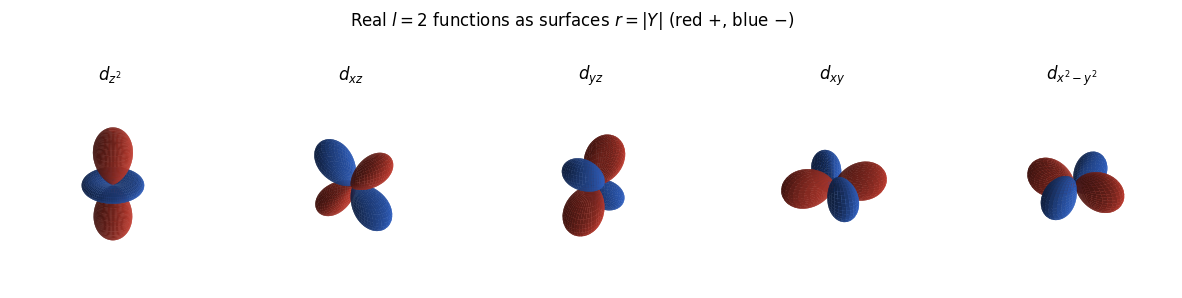

each surface is a mesh: 16471 vertices, 16200 four-sided faces
tip of the d_z2 lobe: r = 0.6308 = sqrt(5/4pi) = 0.6308


In [3]:
def draw(ax, X, Y, Z, sign, title):
    colors = np.where(sign[..., None] >= 0, np.array([0.80, 0.25, 0.20, 1.0]), np.array([0.20, 0.40, 0.80, 1.0]))
    ax.plot_surface(X, Y, Z, facecolors=colors, rstride=2, cstride=2, linewidth=0, antialiased=True, shade=True)
    lim = 0.6
    ax.set(xlim=(-lim, lim), ylim=(-lim, lim), zlim=(-lim, lim), title=title)
    ax.set_box_aspect((1, 1, 1)); ax.set_axis_off()

labels = {"z2": r"$d_{z^2}$", "xz": r"$d_{xz}$", "yz": r"$d_{yz}$", "xy": r"$d_{xy}$", "x2-y2": r"$d_{x^2-y^2}$"}
fig = plt.figure(figsize=(15, 3.4))
for i, name in enumerate(D_ORBITALS):
    ax = fig.add_subplot(1, 5, i + 1, projection="3d")
    draw(ax, *orbital_surface(lambda t, p, name=name: real_d_orbital(name, t, p)), labels[name])
fig.suptitle("Real $l=2$ functions as surfaces $r=|Y|$ (red +, blue −)", y=1.02)
plt.show()

X, Y, Z, sign = orbital_surface(lambda t, p: real_d_orbital("z2", t, p))
print(f"each surface is a mesh: {X.size} vertices, {(X.shape[0]-1)*(X.shape[1]-1)} four-sided faces")
print(f"tip of the d_z2 lobe: r = {np.sqrt(X**2+Y**2+Z**2).max():.4f} = sqrt(5/4pi) = {math.sqrt(5/(4*math.pi)):.4f}")

**For a computer engineer.** "Rendered as a surface" means exactly what
the last two lines print: a grid of $(\theta,\phi)$ samples is mapped to 3-D
vertices, and neighbouring vertices are joined into four-sided faces. A
graphics card draws those faces as pairs of triangles. Finer grids give
smoother lobes at the cost of more vertices.

The complex $Y_2^m$ have $|Y|$ independent of $\phi$, so their surfaces are
figures of revolution with no sign to colour:

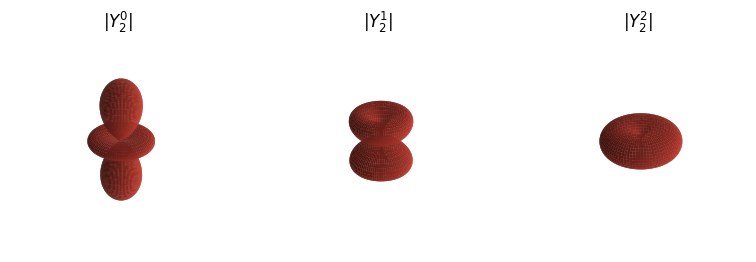

sum of the five squared functions: min 0.397887, max 0.397887, 5/(4 pi) = 0.397887
-> a filled d subshell is perfectly spherical.


In [4]:
fig = plt.figure(figsize=(9.5, 3.4))
for i, m in enumerate((0, 1, 2)):
    ax = fig.add_subplot(1, 3, i + 1, projection="3d")
    draw(ax, *orbital_surface(lambda t, p, m=m: spherical_harmonic(2, m, t, p)), rf"$|Y_2^{{{m}}}|$")
plt.show()

total = sum(real_d_orbital(name, TH, PH)**2 for name in D_ORBITALS)
print(f"sum of the five squared functions: min {total.min():.6f}, max {total.max():.6f}, 5/(4 pi) = {5/(4*math.pi):.6f}")
print("-> a filled d subshell is perfectly spherical.")

# Part 3 — The full wavefunction $\psi_{320}$

The radial part for $n=3$, $l=2$ is ([1], Sec. 4.2)
$$R_{32}(r)=\frac{4}{81\sqrt{30}}\,a^{-3/2}\left(\frac ra\right)^{2}e^{-r/3a}.$$
Left: the radial probability density $r^2R^2$. Right: $|\psi_{320}|^2$ in the
$xz$ plane, showing the two lobes along $z$ and the ring around the equator.

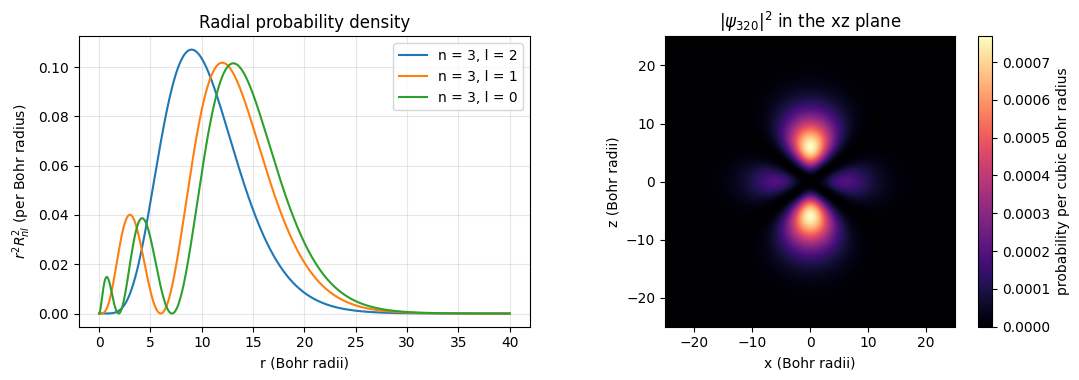

normalization  int R^2 r^2 dr = 0.999998  (grid stops at 40 a)
<r^2> numerically = 126.0000,  formula (n^2/2)(5n^2+1-3l(l+1)) = 126
most probable radius: 9.00 a  (n^2 a = 9 a for the l = n-1 state)


In [5]:
r = np.linspace(0, 40, 4001)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.9))
for n, l in ((3, 2), (3, 1), (3, 0)):
    axes[0].plot(r, r**2 * radial_wavefunction(n, l, r)**2, label=f"n = {n}, l = {l}")
axes[0].set(xlabel="r (Bohr radii)", ylabel=r"$r^2R_{nl}^2$ (per Bohr radius)", title="Radial probability density")
axes[0].legend(); axes[0].grid(alpha=0.3)

x = np.linspace(-25, 25, 401)
XX, ZZ = np.meshgrid(x, x)
RR = np.hypot(XX, ZZ)
theta_xz = np.arctan2(np.abs(XX), ZZ)
density = np.abs(hydrogen_psi(3, 2, 0, RR, theta_xz, np.where(XX >= 0, 0.0, np.pi)))**2
im = axes[1].imshow(density, extent=(-25, 25, -25, 25), origin="lower", cmap="magma")
axes[1].set(xlabel="x (Bohr radii)", ylabel="z (Bohr radii)", title=r"$|\psi_{320}|^2$ in the xz plane")
fig.colorbar(im, ax=axes[1], label="probability per cubic Bohr radius")
fig.tight_layout(); plt.show()

R2 = radial_wavefunction(3, 2, r)**2
print(f"normalization  int R^2 r^2 dr = {np.trapezoid(R2 * r**2, np.linspace(0, 40, 4001)):.6f}  (grid stops at 40 a)")
r_long = np.linspace(0, 120, 120001); R2_long = radial_wavefunction(3, 2, r_long)**2
print(f"<r^2> numerically = {np.trapezoid(R2_long * r_long**4, r_long):.4f},  formula (n^2/2)(5n^2+1-3l(l+1)) = {mean_r2(3, 2):.0f}")
print(f"most probable radius: {r[np.argmax(r**2 * R2)]:.2f} a  (n^2 a = 9 a for the l = n-1 state)")

# Part 4 — Why it is called a quadrupole

Treat $|\psi|^2$ as a charge density $\rho$. Its quadrupole tensor is
$$\Theta_{ij}=\int\rho\,(3x_ix_j-r^2\delta_{ij})\,d^3r ,\qquad
\Theta_{zz}=\langle3z^2-r^2\rangle=\langle r^2\rangle\,(3\langle\cos^2\theta\rangle-1),$$
the same definition used for point charges in
[`dgs/electrostatics_multipoles.py`](../dgs/electrostatics_multipoles.py).
For the 3d states $\langle r^2\rangle=126\,a^2$.

In [6]:
print(f"{'m':>3} {'<cos^2 theta>':>15} {'Theta_zz (a^2)':>16}   shape")
shape = {0: "stretched along z (prolate)", 1: "mildly stretched", 2: "flattened into the xy plane (oblate)"}
for m in (-2, -1, 0, 1, 2):
    print(f"{m:>+3d} {mean_cos2(2, m):>15.4f} {quadrupole_moment_zz(3, 2, m):>+16.1f}   {shape[abs(m)]}")
print(f"sum over m: {sum(quadrupole_moment_zz(3, 2, m) for m in range(-2, 3)):+.1e}  (filled subshell: no quadrupole)")

tensor, charge = quadrupole_tensor(lambda rr, th, p: np.abs(hydrogen_psi(3, 2, 0, rr, th, p))**2, r_max=90.0)
print(f"\nfull tensor for m = 0 by 3-D quadrature (total charge {charge:.6f}):")
print(np.round(tensor, 4))
print(f"trace = {np.trace(tensor):.1e} (a quadrupole tensor is traceless)")

pc = em.quadrupole_moment([1.0, -2.0, 1.0], [[0, 0, 1.0], [0, 0, 0.0], [0, 0, -1.0]])
print("\nfor comparison, three point charges (+1, -2, +1) on the z axis, spacing 1:")
print(np.round(pc, 4), " <- same pattern (-1, -1, 2) x constant")

  m   <cos^2 theta>   Theta_zz (a^2)   shape
 -2          0.1429            -72.0   flattened into the xy plane (oblate)
 -1          0.4286            +36.0   mildly stretched
 +0          0.5238            +72.0   stretched along z (prolate)
 +1          0.4286            +36.0   mildly stretched
 +2          0.1429            -72.0   flattened into the xy plane (oblate)
sum over m: +0.0e+00  (filled subshell: no quadrupole)



full tensor for m = 0 by 3-D quadrature (total charge 1.000000):
[[-36.   0.  -0.]
 [  0. -36.  -0.]
 [ -0.   0.  72.]]
trace = 0.0e+00 (a quadrupole tensor is traceless)

for comparison, three point charges (+1, -2, +1) on the z axis, spacing 1:
[[-2.  0.  0.]
 [ 0. -2.  0.]
 [ 0.  0.  4.]]  <- same pattern (-1, -1, 2) x constant


The orbital and the three point charges have the same tensor pattern
$(-\tfrac12,-\tfrac12,1)\times\Theta_{zz}$. The difference is that the point
charges have **no** net charge, while the orbital has net charge 1 *and* a
quadrupole moment. There is no dipole term in either: both are unchanged by
$\mathbf r\to-\mathbf r$.

# Part 5 — The potential far away

The multipole expansion ([2], Sec. 3.4) for an axially symmetric charge
distribution with no dipole moment reads
$$V(r,\theta)=\frac{1}{4\pi\varepsilon_0}\left[\frac{q}{r}+\frac{\Theta_{zz}\,P_2(\cos\theta)}{2\,r^3}+\dots\right],
\qquad P_2(\cos\theta)=\tfrac12(3\cos^2\theta-1).$$
$P_2$ is $Y_2^0$ up to a constant. The module also computes the **exact**
potential of the cloud by integrating the density, so the expansion can be
tested rather than trusted.

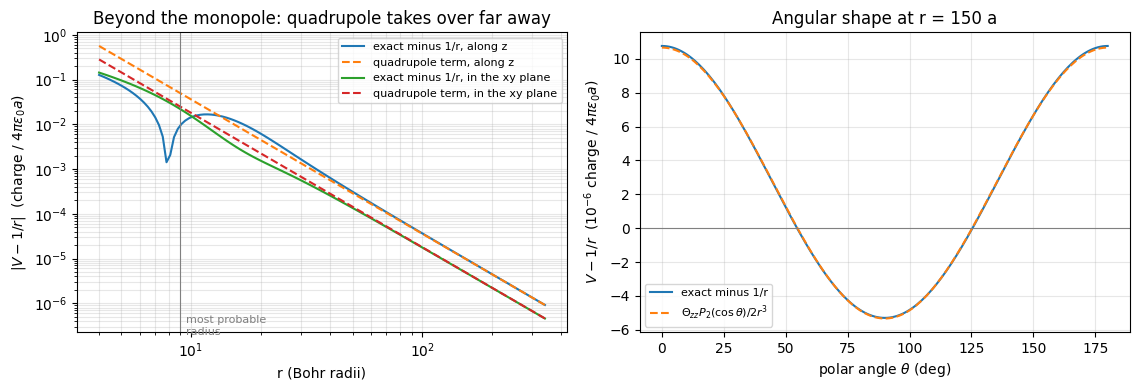

doubling r from 150 a to 300 a:
   (V - 1/r) falls by 8.054   (quadrupole, 1/r^3 -> 8)
   what is left after the quadrupole term falls by 32.000   (next term, 1/r^5 -> 32)
at r = 5 a (inside the cloud) the far-field formula gives 0.488 against an exact 0.127: the expansion is useless there.


In [7]:
r_axis = np.geomspace(4, 340, 120)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))
for angle, label in ((0.0, "along z"), (np.pi/2, "in the xy plane")):
    exact = orbital_potential(3, 2, 0, r_axis, angle)
    quad = far_field_potential(3, 2, 0, r_axis, angle) - 1/r_axis
    axes[0].loglog(r_axis, np.abs(exact - 1/r_axis), label=f"exact minus 1/r, {label}")
    axes[0].loglog(r_axis, np.abs(quad), "--", label=f"quadrupole term, {label}")
axes[0].axvline(9, color="gray", lw=0.8); axes[0].text(9.5, 2e-7, "most probable\nradius", fontsize=8, color="gray")
axes[0].set(xlabel="r (Bohr radii)", ylabel=r"$|V-1/r|$  (charge / $4\pi\varepsilon_0 a$)",
            title="Beyond the monopole: quadrupole takes over far away")
axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3, which="both")

angles = np.linspace(0, np.pi, 181)
r0 = 150.0
exact_ang = orbital_potential(3, 2, 0, r0, angles) - 1/r0
axes[1].plot(np.degrees(angles), exact_ang * 1e6, label="exact minus 1/r")
axes[1].plot(np.degrees(angles), (far_field_potential(3, 2, 0, r0, angles) - 1/r0) * 1e6, "--", label=r"$\Theta_{zz}P_2(\cos\theta)/2r^3$")
axes[1].axhline(0, color="gray", lw=0.8)
axes[1].set(xlabel=r"polar angle $\theta$ (deg)", ylabel=r"$V-1/r$  ($10^{-6}$ charge / $4\pi\varepsilon_0 a$)",
            title=f"Angular shape at r = {r0:.0f} a")
axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)
fig.tight_layout(); plt.show()

for r1, r2 in ((150.0, 300.0),):
    beyond = orbital_potential(3, 2, 0, np.array([r1, r2]), 0.0) - 1/np.array([r1, r2])
    rest = orbital_potential(3, 2, 0, np.array([r1, r2]), 0.0) - far_field_potential(3, 2, 0, np.array([r1, r2]), 0.0)
    print(f"doubling r from {r1:.0f} a to {r2:.0f} a:")
    print(f"   (V - 1/r) falls by {beyond[0]/beyond[1]:.3f}   (quadrupole, 1/r^3 -> 8)")
    print(f"   what is left after the quadrupole term falls by {rest[0]/rest[1]:.3f}   (next term, 1/r^5 -> 32)")
print(f"at r = 5 a (inside the cloud) the far-field formula gives {far_field_potential(3, 2, 0, 5.0, 0.0):.3f} "
      f"against an exact {orbital_potential(3, 2, 0, 5.0, 0.0):.3f}: the expansion is useless there.")

Far from the atom the departure from a point charge follows the
quadrupole term in both its $1/r^3$ fall-off and its $P_2$ angular shape.
What remains after subtracting it falls as $1/r^5$: that is the next allowed
term, $L=4$, because $|Y_2^0|^2$ contains $P_0$, $P_2$ and $P_4$ and nothing
else. Inside the cloud the expansion fails, as it must: it assumes the
observer is outside all the charge.

# What this notebook does and does not show

| Shown, with numbers | Not shown |
|---|---|
| $Y_2^m$ are orthonormal; five real combinations sum to a sphere | spin, fine structure, or any atom other than hydrogen |
| $\langle r^2\rangle=126a^2$ and $\Theta_{zz}=72,\,36,\,-72\,a^2$ for 3d, $m=0,\pm1,\pm2$ | how a quadrupole moment is measured |
| far-field potential $=$ monopole $+$ quadrupole, error $\propto1/r^5$ | quadrupole *radiation* (a different, time-dependent topic) |
| the surface is a mesh of vertices and faces | an isosurface of $\lvert\psi\rvert^2$ (the plots are $r=\lvert Y\rvert$ and a 2-D slice) |

The static charge-cloud picture is a teaching device. A hydrogen atom in a
stationary state does have this time-independent charge density, but a real
atom's interaction with its surroundings involves more than electrostatics.

**Exercises**

1. Use `quadrupole_moment_zz` for the 2p states. Which $m$ is prolate?
2. Change `n_theta` and `n_phi` in `orbital_surface` to 11 and 21. How many
   faces is the coarsest mesh that still looks like $d_{z^2}$?
3. Verify $\langle\cos^2\theta\rangle=11/21$ for $Y_2^0$ by hand, using the
   integral $\int_{-1}^{1}\mu^2(3\mu^2-1)^2\,d\mu$.
4. For which $l$ would the far-field correction start with an octupole? Why
   can that never happen for $|\psi|^2$?

# References

[1] D. J. Griffiths and D. F. Schroeter, *Introduction to Quantum Mechanics*,
3rd ed. Cambridge, U.K.: Cambridge Univ. Press, 2018, Sec. 4.1.2
(spherical harmonics) and Sec. 4.2 (the hydrogen atom).

[2] D. J. Griffiths, *Introduction to Electrodynamics*, 4th ed. Cambridge,
U.K.: Cambridge Univ. Press, 2017, Sec. 3.4 (multipole expansion).

Section numbers are from the editions listed; check them against your copy.